# DQN with Experience Replay and Target Network — Instructor Solution

**Intelligent Agents · UC2 · §2.2** — reference implementation for the lab guide *"DQN with Experience Replay and Target Network"*.

This notebook mirrors the guide: Parts 1–3 build the components and run the same self-checks students receive, Part 4 trains the full DQN on CartPole-v1, and Part 5 runs the ablations. An **answer key** for every report question follows each part.

> **Instructor only — do not distribute.**

Run time: Part 4 is one training run; Part 5 trains 3 seeds × 7 configurations (plus 3 extra buffer sizes if you enable them), so run it before class or reduce `STEPS`.

In [2]:
# !pip install torch gymnasium numpy matplotlib   # uncomment on a fresh environment
import os

os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')

import copy, random, time
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| gymnasium", gym.__version__)

torch 2.14.0 | gymnasium 1.0.0


## Part 1 — Replay buffer

Uniform random experience replay as in the reading (Algorithm *Uniform random experience replay*):

- `add(d)`: insertion index $i = c \bmod N$, store at $i$ (overwriting the oldest), $c \leftarrow c+1$
- `sample(n)`: only if $c \ge n$; draw $n$ indices uniformly from $[0, \min(c, N))$

Each field lives in its own preallocated NumPy array, so adding is $O(1)$ and a mini-batch is one fancy-indexing call.

In [3]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.N = capacity
        self.c = 0                                   # transitions ever added
        self.s    = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a    = np.zeros(capacity, dtype=np.int64)
        self.r    = np.zeros(capacity, dtype=np.float32)
        self.s2   = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        i = self.c % self.N                          # 1.1 insertion index
        self.s[i], self.a[i], self.r[i] = s, a, r    # 1.2 write (overwrites oldest)
        self.s2[i], self.done[i] = s2, done
        self.c += 1                                  # 1.3

    def __len__(self):
        return min(self.c, self.N)                   # 1.4 valid transitions

    def sample(self, n):
        if self.c < n:                               # 1.5
            return None
        idx = np.random.randint(0, len(self), size=n)  # 1.6 uniform in [0, min(c, N))
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.done[idx]

In [4]:
# Self-check (identical to the students' version): slide example, N = 8, d0 ... d11
buf = ReplayBuffer(capacity=8, state_dim=4)
assert buf.sample(4) is None, "must refuse to sample before c >= n"
for k in range(11):                                  # add d0 ... d10
    buf.add(np.full(4, k), k % 2, float(k), np.full(4, k + 1), 0.0)
assert len(buf) == 8 and buf.c == 11
assert buf.r[3] == 3.0                               # slot 3 still holds d3
buf.add(np.full(4, 11), 1, 11.0, np.full(4, 12), 1.0)  # d11
assert buf.r[3] == 11.0, "d11 must overwrite slot 11 mod 8 = 3"
batches = [buf.sample(8) for _ in range(200)]
r  = np.concatenate([b[2] for b in batches])
s  = np.concatenate([b[0] for b in batches])
s2 = np.concatenate([b[3] for b in batches])
assert set(r.tolist()) == set(range(4, 12)), "samples must cover the whole buffer"
assert np.all(s2[:, 0] == s[:, 0] + 1), "fields of one transition must stay aligned"
print("ReplayBuffer: all checks passed")

ReplayBuffer: all checks passed


### Answer key — Part 1

1. **Why `[0, min(c, N))`?** Until the buffer has wrapped once, only the first $c$ slots hold real transitions; the rest are the zero-initialised placeholders. Sampling from $[0, N)$ early on would feed fake all-zero transitions (state 0, reward 0, not done) into the loss.
2. **Why a ring buffer instead of `list` + `pop(0)`?** `pop(0)` shifts every element, so each insertion costs $O(N)$ — about 50,000 moves per step at $N = 50{,}000$. The ring buffer overwrites in $O(1)$, memory is preallocated once, and contiguous arrays make random mini-batch indexing a single vectorised call. (A `collections.deque(maxlen=N)` fixes insertion, but random access into the middle of a deque is $O(N)$.)
3. **Where is `done` needed?** In the target (line 12 of the DQN algorithm): if $s_{j+1}$ is terminal, $\delta_j = r_j$ with no bootstrap term. Without the flag the learner would add $\gamma \max_{a'} \hat Q(s_{j+1}, a')$ for states after which nothing more can happen.

## Part 2 — Q-network and ε-greedy action selection

A 4 → 128 → 128 → 2 MLP: one forward pass returns $\hat Q(s, a; \theta)$ for **every** action. No activation on the output layer.

In [5]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(                    # 2.1
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)                           # shape: (batch, n_actions)


def select_action(q_net, s, eps, n_actions):
    # 2.2  epsilon-greedy with respect to the ONLINE network θ
    if random.random() < eps:
        return random.randrange(n_actions)
    with torch.no_grad():
        q = q_net(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))
    return int(q.argmax(dim=1).item())

In [6]:
q = QNetwork(4, 2)
out = q(torch.zeros(32, 4))
assert out.shape == (32, 2)
assert sum(p.numel() for p in q.parameters()) == 4*128+128 + 128*128+128 + 128*2+2
assert select_action(q, np.zeros(4, dtype=np.float32), 0.0, 2) in (0, 1)
print("QNetwork: all checks passed")

QNetwork: all checks passed


### Answer key — Part 2

1. **Why output $Q(s,\cdot)$ for all actions?** Both uses of the network need all actions at once: ε-greedy needs $\arg\max_a \hat Q(s,a)$ and the target needs $\max_{a'} \hat Q(s', a')$. With $|A|$ outputs that is one forward pass; with $(s, a)$ as input it would take $|A|$ passes per state. It also lets the actions share the learned state features.
2. **Why no ReLU on the last layer?** Q-values are returns, which can be any real number (negative whenever rewards are negative). A ReLU would clip them to $\ge 0$ and, for any output stuck below zero, give zero gradient so that action's value could never be corrected. (In CartPole the true values happen to be positive, but the network should not hard-code that.)

## Part 3 — Target network and loss

$$
\delta_j = \begin{cases} r_j & \text{if } s_{j+1} \text{ is terminal} \\ r_j + \gamma \max_{a'} \hat{Q}(s_{j+1}, a'; \theta^-) & \text{otherwise} \end{cases}
\qquad
l = \frac{1}{b}\sum_j \big(\delta_j - \hat{Q}(s_j, a_j; \theta)\big)^2
$$

Implemented with a mask: $\delta = r + \gamma (1 - \text{done}) \max_{a'} \hat Q(s', a'; \theta^-)$, computed under `torch.no_grad()` so θ⁻ never receives gradients.

In [7]:
def compute_loss(q_net, target_net, batch, gamma):
    s, a, r, s2, done = (torch.as_tensor(x) for x in batch)
    q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)          # 3.1  Q(s_j, a_j; θ)
    with torch.no_grad():
        max_next = target_net(s2).max(dim=1).values               # 3.2  max_a' Q(s_{j+1}, a'; θ⁻)
        delta = r + gamma * (1.0 - done) * max_next               # 3.3  terminal → δ = r
    return nn.functional.mse_loss(q_sa, delta)                    # 3.4

In [8]:
torch.manual_seed(0)
q = QNetwork(4, 2)
qt = copy.deepcopy(q)
b = 16
batch = (np.random.randn(b, 4).astype(np.float32), np.random.randint(0, 2, b),
         np.ones(b, np.float32), np.random.randn(b, 4).astype(np.float32),
         np.ones(b, np.float32))                       # all terminal
loss = compute_loss(q, qt, batch, gamma=0.99)
q_sa = q(torch.as_tensor(batch[0])).gather(1, torch.as_tensor(batch[1]).unsqueeze(1)).squeeze(1)
assert torch.isclose(loss, ((q_sa - 1.0) ** 2).mean()), "terminal target must be r"
loss.backward()
assert all(p.grad is None for p in qt.parameters()), "no gradient may reach θ⁻"

# Extra instructor check: non-terminal targets must use θ⁻, not θ
batch_nt = batch[:4] + (np.zeros(b, np.float32),)
with torch.no_grad():
    for p in qt.parameters():
        p.add_(0.5)                                     # make θ⁻ differ from θ
    expected = torch.as_tensor(batch[2]) + 0.99 * qt(torch.as_tensor(batch[3])).max(1).values
    q_sa = q(torch.as_tensor(batch[0])).gather(1, torch.as_tensor(batch[1]).unsqueeze(1)).squeeze(1)
assert torch.isclose(compute_loss(q, qt, batch_nt, 0.99), ((q_sa - expected) ** 2).mean())
print("compute_loss: all checks passed")

compute_loss: all checks passed


### Answer key — Part 3

1. **Forgetting `torch.no_grad()`** — the target becomes part of the computation graph. Gradients then also push $\hat Q(s', \cdot)$ toward $\hat Q(s, a)$ (a "residual-gradient" update, not Q-learning). If the optimiser also holds θ⁻'s parameters, the target network is trained every step, is no longer frozen, and we are back to chasing a moving target. Even when θ⁻'s parameters are not in the optimiser, `backward()` wastes time and memory filling their `.grad`.
2. **`target_net = q_net` instead of `deepcopy`** — both names point to the *same* module, so the "target" changes with every gradient step. The algorithm silently becomes DQN without a target network (run B), with no error message.

**Terminated vs truncated (common bug to look for when grading):** `done` must be `terminated` only. A time-limit truncation at 500 steps is not a real end: the pole is still up and the state still has value, so the target must bootstrap.

## Part 4 — Training loop

Line numbers refer to *Deep Q-learning with experience replay and target network* in the reading.

| Symbol | Argument | Value |
| --- | --- | --- |
| K | `steps` | 50,000 |
| N | `capacity` | 50,000 |
| b | `batch` | 64 |
| m | `warmup` | 1,000 |
| C | `C` | 500 |
| γ | `gamma` | 0.99 |
| α | `lr` (Adam) | 0.001 |
| ε | `eps_end`, `eps_decay` | 1.0 → 0.05 over 10,000 steps |

In [9]:
def epsilon_by_step(i, eps_start, eps_end, eps_decay):
    return eps_start + min(1.0, i / eps_decay) * (eps_end - eps_start)


def train(steps=50_000, capacity=50_000, batch=64, warmup=1_000, C=500,
          gamma=0.99, lr=1e-3, eps_end=0.05, eps_decay=10_000,
          use_target=True, seed=0, return_model=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)
    state_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    q_net = QNetwork(state_dim, n_actions)
    target_net = copy.deepcopy(q_net)                      # θ⁻ ← θ
    target_net.eval()
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    buf = ReplayBuffer(capacity, state_dim)

    s, _ = env.reset(seed=seed)                            # line 1
    ep_ret, log = 0.0, []                                  # log: (step, return)
    for i in range(1, steps + 1):                          # line 2
        eps = epsilon_by_step(i, 1.0, eps_end, eps_decay)  # 4.1  line 6
        a = select_action(q_net, s, eps, n_actions)        # 4.2  line 3
        s2, r, terminated, truncated, _ = env.step(a)      #      line 4
        buf.add(s, a, r, s2, float(terminated))            # 4.3  line 7 (terminated only!)
        s = s2                                             #      line 8
        ep_ret += r
        if terminated or truncated:                        # 4.4
            log.append((i, ep_ret))
            ep_ret = 0.0
            s, _ = env.reset()

        if len(buf) > warmup and len(buf) > batch:         # line 9
            mb = buf.sample(batch)                         # 4.5  line 10
            tgt = target_net if use_target else q_net
            loss = compute_loss(q_net, tgt, mb, gamma)     #      lines 11–14
            opt.zero_grad()
            loss.backward()
            opt.step()                                     #      line 15
            if i % C == 0:                                 # 4.6  lines 16–17
                target_net.load_state_dict(q_net.state_dict())
    env.close()
    return (log, q_net) if return_model else log


def evaluate(q_net, episodes=10, seed=100):
    env = gym.make("CartPole-v1")
    rets = []
    for k in range(episodes):
        s, _ = env.reset(seed=seed + k)
        done, total = False, 0.0
        while not done:
            a = select_action(q_net, s, 0.0, env.action_space.n)   # greedy
            s, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
        rets.append(total)
    env.close()
    return np.mean(rets), np.std(rets)

In [10]:
# Random-policy baseline (ε = 1 throughout, so the network is never used for acting)
t0 = time.time()
base_log = train(steps=20_000, eps_end=1.0, seed=0)
baseline = np.mean([ret for _, ret in base_log])
print(f"random baseline: mean return {baseline:.1f} over {len(base_log)} episodes ({time.time()-t0:.0f}s)")

random baseline: mean return 22.0 over 908 episodes (9s)


428 episodes in 21s | last 20 episodes: 388.8 | best: 500
greedy evaluation (10 episodes): mean 500.0 ± 0.0


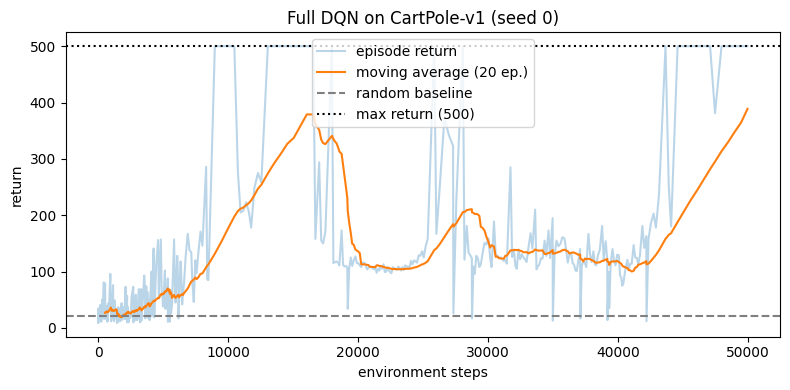

In [11]:
# Full DQN, one seed
t0 = time.time()
log, q_trained = train(seed=0, return_model=True)
steps_, rets_ = map(np.array, zip(*log))
print(f"{len(log)} episodes in {time.time()-t0:.0f}s | last 20 episodes: {rets_[-20:].mean():.1f} | best: {rets_.max():.0f}")
print("greedy evaluation (10 episodes): mean %.1f ± %.1f" % evaluate(q_trained))

plt.figure(figsize=(8, 4))
plt.plot(steps_, rets_, alpha=0.3, label="episode return")
w = 20
plt.plot(steps_[w-1:], np.convolve(rets_, np.ones(w)/w, mode="valid"), label=f"moving average ({w} ep.)")
plt.axhline(baseline, ls="--", c="gray", label="random baseline")
plt.axhline(500, ls=":", c="k", label="max return (500)")
plt.xlabel("environment steps"); plt.ylabel("return"); plt.title("Full DQN on CartPole-v1 (seed 0)")
plt.legend(); plt.tight_layout(); plt.show()

### Grading notes — Part 4

Checklist for reading student code:

- ε-greedy uses the **online** network θ (line 3), not θ⁻.
- Training starts only when $|D| > m$ **and** $|D| > b$ (line 9).
- `zero_grad → backward → step` in that order; the optimiser holds `q_net.parameters()` only.
- Target sync uses `load_state_dict` (copy), not assignment.
- `done = terminated` (not `terminated or truncated`).

If a student's run never beats the random baseline, the usual suspects are: no `opt.step()`, gathering the wrong action column, `done` mask inverted (`done` instead of `1 - done`), or the prediction computed with `target_net`.

## Part 5 — Experiments

3 seeds per configuration; curves are the 20-episode moving average interpolated on a common step grid, shown as mean ± one standard deviation across seeds. Set `STEPS` lower for a quick demo.

In [12]:
STEPS = 50_000
SEEDS = (0, 1, 2)

def curve(log, grid, window=20):
    steps, rets = map(np.array, zip(*log))
    smooth = np.convolve(rets, np.ones(window) / window, mode="valid")
    return np.interp(grid, steps[window - 1:], smooth)

def run_configs(runs, steps=STEPS):
    grid = np.linspace(5_000, steps, 200)
    results = {}
    for label, kwargs in runs.items():
        t0 = time.time()
        results[label] = np.stack([curve(train(steps=steps, seed=sd, **kwargs), grid) for sd in SEEDS])
        print(f"{label:>16}: final {results[label][:, -1].mean():6.1f} ± {results[label][:, -1].std():5.1f}"
              f"   ({time.time()-t0:.0f}s)")
    return grid, results

def plot(grid, results, title, path):
    plt.figure(figsize=(8, 4.5))
    for label, ys in results.items():
        m, sd = ys.mean(0), ys.std(0)
        plt.plot(grid, m, label=label)
        plt.fill_between(grid, m - sd, m + sd, alpha=0.2)
    plt.axhline(baseline, ls="--", c="gray", lw=1, label="random baseline")
    plt.xlabel("environment steps"); plt.ylabel("episode return (moving avg, 20 ep.)")
    plt.title(title); plt.legend(); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

      A full DQN: final  263.3 ±  91.4   (63s)
     B no target: final  263.1 ±  50.6   (63s)
   C tiny buffer: final  154.0 ±  48.5   (63s)


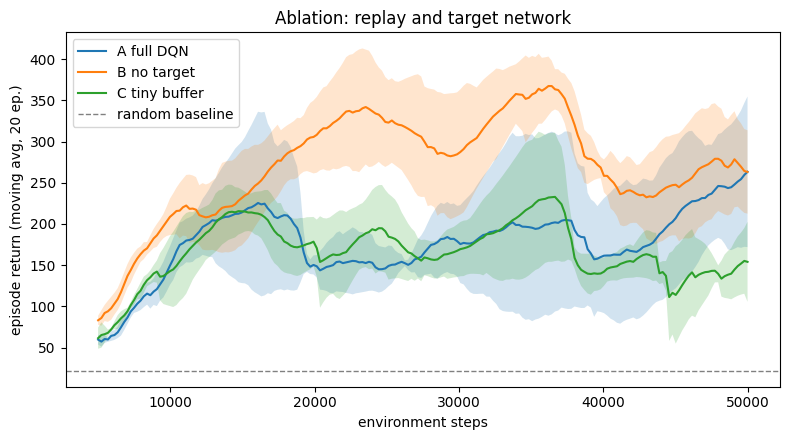

In [13]:
# Runs A–C: ablation of replay and target network
grid, res_abl = run_configs({
    "A full DQN":    {},
    "B no target":   {"use_target": False},
    "C tiny buffer": {"capacity": 128, "warmup": 64},
})
plot(grid, res_abl, "Ablation: replay and target network", "ablation.png")

           C = 1: final  263.1 ±  50.6   (77s)
         C = 100: final  461.4 ±  24.1   (66s)
         C = 500: final  263.3 ±  91.4   (64s)
        C = 2000: final  196.4 ±  78.7   (66s)


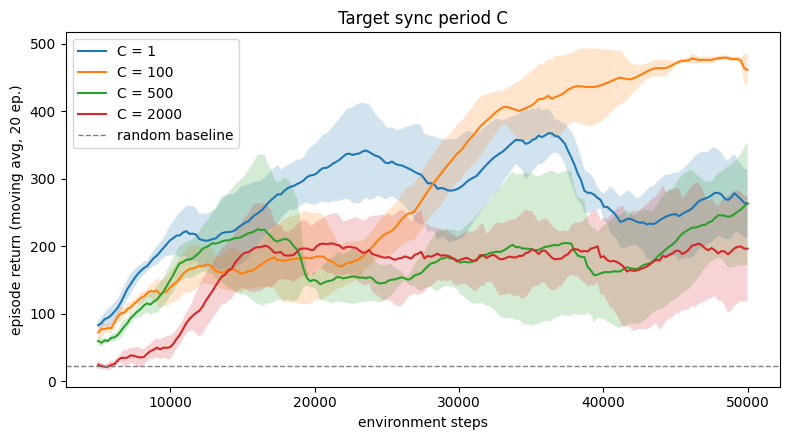

C = 1 identical to no target network: True


In [14]:
# Run D: target sync period C
grid, res_C = run_configs({f"C = {c}": {"C": c} for c in (1, 100, 500, 2000)})
plot(grid, res_C, "Target sync period C", "sync_period.png")

# Sanity check for question 3: C = 1 and "no target" should match exactly for the same seed
log_c1 = train(steps=5_000, C=1, seed=0)
log_nt = train(steps=5_000, use_target=False, seed=0)
print("C = 1 identical to no target network:", log_c1 == log_nt)

       N = 1,000: final   37.2 ±  39.2   (5s)
      N = 10,000: final  312.9 ± 127.5   (63s)
      N = 50,000: final  263.3 ±  91.4   (63s)


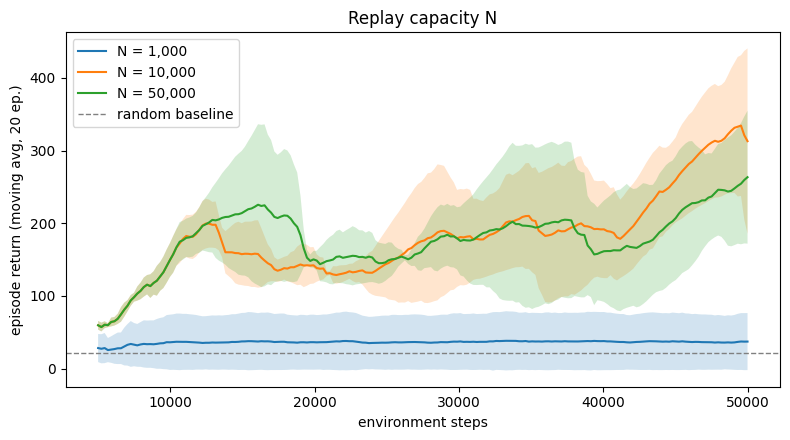

In [15]:
# Run E: buffer size (optional — 9 more training runs)
grid, res_N = run_configs({f"N = {n:,}": {"capacity": n} for n in (1_000, 10_000, 50_000)})
plot(grid, res_N, "Replay capacity N", "buffer_size.png")

### Answer key — Part 5

Exact numbers vary by seed and machine; grade the reasoning and whether it matches the student's own plots. Expected tendencies:

1. **Ranking A, B, C.** A (full DQN) should reach the highest final return with the smallest spread across seeds. B (no target network) usually learns too, but less stably: returns rise and then collapse, and the band across seeds is wider — the moving-target feedback loop. C (tiny buffer) is typically the weakest or most erratic: each mini-batch comes from the last ~128 steps, so samples are highly correlated (non-IID) and the network keeps overwriting what it learned in other parts of the state space; old experience is also discarded almost immediately (poor data efficiency).
2. **Sync period C.** Small C (1, 100) tracks θ closely: fresh targets and often fast early progress, but more oscillation. Large C (2000) is the most stable between syncs but learns slowly, because the targets are stale — the staircase of θ⁻ has long, flat steps. Intermediate values (≈ 500) are usually the best compromise.
3. **Does C = 1 behave like B?** Yes — it is the same algorithm. With C = 1 the copy happens after every gradient step, so at the next loss computation θ⁻ = θ exactly. Because both versions also use `no_grad` on the target, the runs are identical for the same seed (the sanity-check cell should print `True`). A target network only helps when it lags behind θ.
4. **Why can a very large buffer slow early learning?** A large buffer keeps transitions from the early, near-random policy for a long time, so new and more informative transitions make up a small share of each mini-batch, and the learner adapts more slowly to its improving policy. The trade-off: small buffers → correlated, quickly forgotten data; very large buffers → stale data and more memory.